# Practical 3: Maximum and Minimum Elements in an Array (Pattern 1)

### 1. Aim
To find maximum and minimum elements from a large array across 4 methods: Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Create array tasks of integers using random number generation.<br>2. Sequential: execute the 3 tasks sequentially.<br>3. Pool: pass the tasks across 3 worker processes in `mp.Pool(3)`.<br>4. Process: spawn 3 separate `mp.Process` instances.<br>5. Thread: launch 3 concurrent worker threads.<br>6. Record execution times and compute speedups.

### 3. Python Implementation


In [1]:
"""
Practical 3: Program to find maximum and minimum elements from an array
Pattern 1: Same task executed across 3 workers
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def find_min_max_task(task):
    size, seed = task
    rng = np.random.default_rng(seed)
    arr = rng.integers(1, 1_000_000_000, size=size)
    return int(np.min(arr)), int(np.max(arr))

def proc_worker(task, q):
    q.put(find_min_max_task(task))

def thread_worker(task, results, idx):
    results[idx] = find_min_max_task(task)

def main():
    print("=" * 60)
    print("Practical 3: Maximum and Minimum in an Array")
    print("=" * 60)
    SIZE = 40_000_000
    tasks = [(SIZE, 101), (SIZE, 202), (SIZE, 303)]
    
    # 1. Sequential: Execute 3 tasks sequentially
    t0 = time.perf_counter()
    r1 = find_min_max_task(tasks[0])
    r2 = find_min_max_task(tasks[1])
    r3 = find_min_max_task(tasks[2])
    t_seq = time.perf_counter() - t0
    
    # 2. Pool: 3 workers
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(find_min_max_task, tasks)
    t_pool = time.perf_counter() - t0
    
    # 3. Process: 3 independent processes
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for t in tasks:
        p = mp.Process(target=proc_worker, args=(t, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    
    # 4. Multithreading: 3 threads
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, t in enumerate(tasks):
        th = threading.Thread(target=thread_worker, args=(t, th_res, i))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    
    print(f"Array Size: {SIZE:,} elements per task")
    print(f"[Sequential] Min: {r1[0]:,} | Max: {r1[1]:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Min: {p_res[0][0]:,} | Max: {p_res[0][1]:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Min: {pr_res[0][0]:,} | Max: {pr_res[0][1]:,} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Min: {th_res[0][0]:,} | Max: {th_res[0][1]:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Min-Max Search)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("03_max_min_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, speedups, color=colors)
    plt.title("Speedup Comparison relative to Sequential", fontsize=13)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.2f}x", ha='center', va='bottom', fontsize=10)
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("03_max_min_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '03_max_min_time.png' and '03_max_min_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 3: Maximum and Minimum in an Array
Array Size: 40,000,000 elements per task
[Sequential] Min: 6 | Max: 999,999,989 | Time: 1.6506s
[Pool]       Min: 6 | Max: 999,999,989 | Time: 1.3430s
[Process]    Min: 13 | Max: 999,999,964 | Time: 1.3545s
[Thread]     Min: 6 | Max: 999,999,989 | Time: 0.4915s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   1.6506 seconds      1.00x
Pool         1.3430 seconds      1.23x
Process      1.3545 seconds      1.22x
Thread       0.4915 seconds      3.36x
---------------------------------------------
Graphs saved as '03_max_min_time.png' and '03_max_min_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
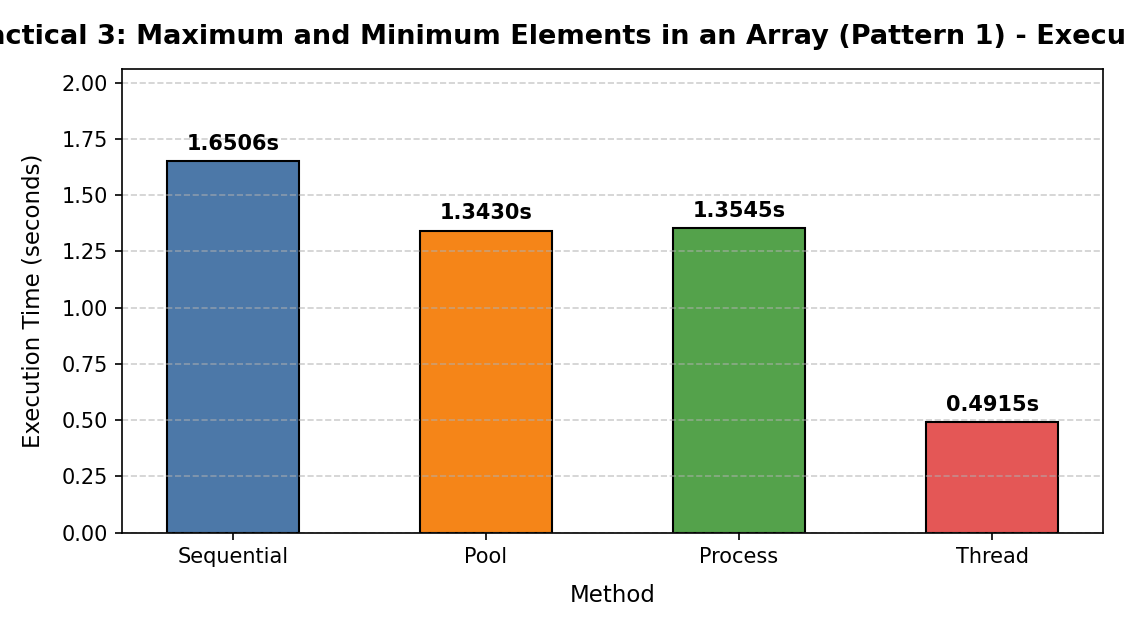

#### B. Speedup Comparison relative to Sequential
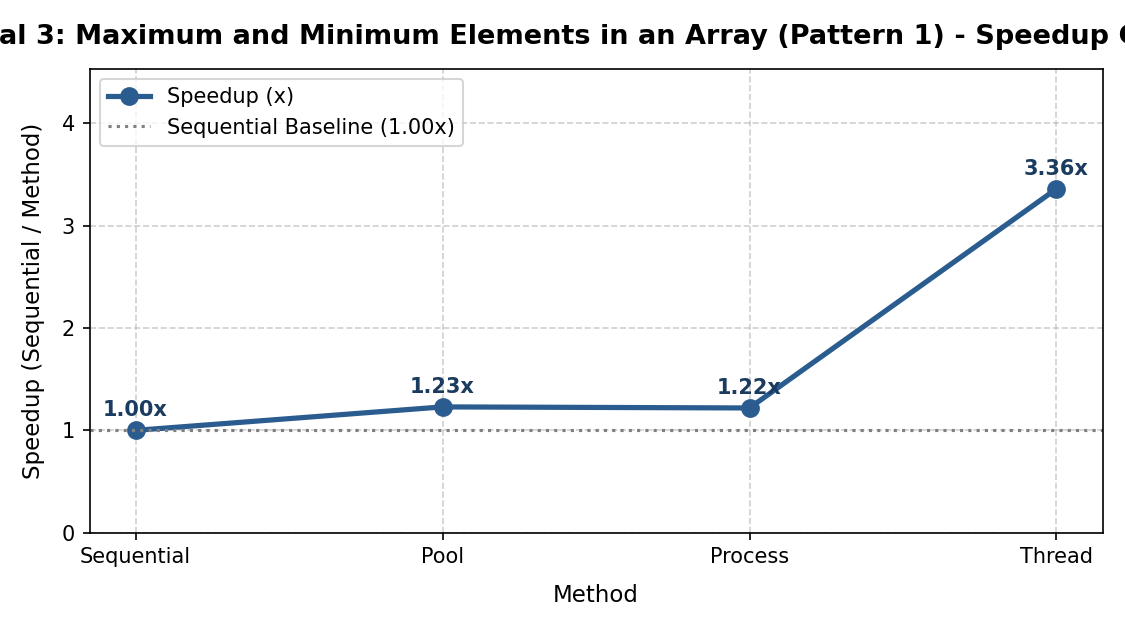
